# Is my data spatial?

Before any biology, a spatial receptor data set has to answer one question: do the receptor molecules (or calls) sit
where their cells were? This notebook asks it of two public data sets with the same code:

* **AIR-SPACE** (Jiang et al., *PNAS* 2026; GEO GSE286452): a mouse popliteal lymph node 14 days after vaccinia
  infection, Curio Seeker 10 µm beads, nanopore reads that carry the V(D)J, the constant region, the bead barcode and
  a UMI on one molecule;
* **Stereo-XCR-seq LUAD** (Zhan et al., *Nat Commun* 2026; GEO GSE328481): human lung adenocarcinoma on a Stereo-seq
  chip, with the authors' per-cell receptor calls on segmented cells (chip D06047A2).

**Reading rule, fixed before looking at the results.** Tests that need a cell to carry *its own* receptor decide:
the molecule sits on a spot holding its own constant-region transcript, cells of one clone sit near each other beyond
what their local Ig RNA explains, heavy and light chains of one cell share a bin. Density metrics (receptors follow B
cells, receptor-positive cells express Ig genes) are reported but cannot decide, because a library whose barcodes come
from random captured cDNA follows RNA density too. Section 4 makes this concrete with placebos.

In [1]:
import os
import warnings
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from scipy.stats import spearmanr

import spaclone
from spaclone import gex, io, nulls, pl, pp, qc, tl

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 60)
plt.rcParams["figure.dpi"] = 100
warnings.formatwarning = lambda message, category, *args, **kwargs: f"{category.__name__}: {message}\n"  # one-line warnings
print("spaclone", spaclone.__version__)
print(" | ".join(f"{p} {version(p)}" for p in ("numpy", "pandas", "scipy", "anndata", "scanpy", "matplotlib")))

spaclone 1.0.1
numpy 2.5.4 | pandas 3.1.0 | scipy 1.18.1 | anndata 0.13.4 | scanpy 1.12.5 | matplotlib 3.11.2


## The data

Both data sets are public.

* **AIR-SPACE** (built in): `spaclone.datasets.airspace("D14")` downloads the bead counts and the clone table of
  the D14 node from GEO once (about 94 MB; needs `pip install "spaclone[datasets]"`), checks their sha256 and
  returns the two paths. Files go to the user cache, or to the folder in the environment variable
  `SPACLONE_DATA_DIR`; later calls only verify them. All six nodes (Mock, D3, D7, D10, D14, D21) are built in.
* **Stereo-XCR-seq LUAD** (not built in, 0.98 GB): chip D06047A2 is GEO sample GSM9684211 of series GSE328481
  (https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE328481), supplementary file `GSM9684211_D06047A2.h5ad`.
  Download it and either put it next to this notebook or set the environment variable `SPACLONE_LUAD_H5AD` to
  its path.

In [2]:
D14_H5AD, D14_CLONES = spaclone.datasets.airspace("D14")
LUAD_H5AD = Path(os.environ.get("SPACLONE_LUAD_H5AD", "GSM9684211_D06047A2.h5ad"))  # see "The data"
COLS = ["test", "locus", "n", "observed", "chance", "ratio", "p_value", "q_value", "verdict", "note"]

## 1. AIR-SPACE, lymph node D14

`io.read_airspace` reads the bead counts of every bead (off-tissue beads included) and the per-read MiXCR table, and
collapses reads into molecules: one record per (bead, UMI, chain). Coordinates become micrometres (one Curio unit is
0.65 µm), and beads are called on or off the tissue with the authors' rule (≥ 100 counts and ≥ 15 such beads within
100 µm).

In [3]:
sp = io.read_airspace(D14_H5AD, D14_CLONES)
print({k: sp.meta[k] for k in ("technology", "level", "n_beads", "n_tissue_beads", "n_reads", "n_records")})
sp.air[["spot_id", "x_um", "y_um", "locus", "clone_id", "junction_aa", "v_call", "c_call", "consensus_count", "umi", "in_tissue"]].head()

{'technology': 'AIR-SPACE (Curio Seeker + R2C2 nanopore)', 'level': 'molecule', 'n_beads': 78224, 'n_tissue_beads': 21477, 'n_reads': 28268, 'n_records': 25504}


,spot_id,x_um,y_um,locus,clone_id,junction_aa,v_call,c_call,consensus_count,umi,in_tissue
0,GATGTGTGTTAGGA,1989.325,3336.515,IGH,1044,CARIATYYGNYDYW,IGHV8-8*00,IGHG1,1.0,AAATGCT,False
1,CCCCTCTCATTAAC,1282.060,2932.995,IGH,1044,CARIATYYGNYDYW,IGHV8-8*00,IGHG1,1.0,CCTGATT,True
2,AACCATATCCTCGT,2254.070,1216.085,IGH,2088,CAQGEYW,IGHV8-5*00,IGHG1,1.0,TCATGAG,True
3,ACTCTTACGGGACC,1367.405,1612.195,TRB,516,CASRGTGNTEVFF,TRBV19*00,TRBC1,1.0,GGGCGCA,True
4,CTCCCTACACCTGT,2672.475,2886.130,TRB,150,CASSLGGRVGQNTLYF,TRBV15*00,TRBC2,45.0,TTTTTTT,True


### Receptor QC

`pp.qc_metrics` summarises the table per chain: records, spots, clones, read support, valid and productive shares,
clones per spot, the off-tissue share and the share of records on barcode sinks (spots with ≥ 20 clones).
`pl.qc_panel` draws the same in four panels.

In [4]:
qc_sp = pp.qc_metrics(sp.air)
show = ["n_records", "n_spots", "n_clones", "share_single_read", "valid_share", "share_spots_one_clone",
        "off_tissue_share", "sink_record_share"]
qc_sp.table.set_index("locus")[show].round(3)

,n_records,n_spots,n_clones,share_single_read,valid_share,share_spots_one_clone,off_tissue_share,sink_record_share
locus,,,,,,,,
IGH,2185,1408,552,0.949,0.988,0.850,0.168,0.032
IGK,19798,8187,1233,0.970,0.983,0.659,0.175,0.021
IGL,2521,1355,37,0.944,0.989,0.942,0.191,0.008
TRA,123,75,59,0.829,0.967,0.973,0.163,0.008
TRB,877,582,393,0.811,0.983,0.916,0.212,0.000


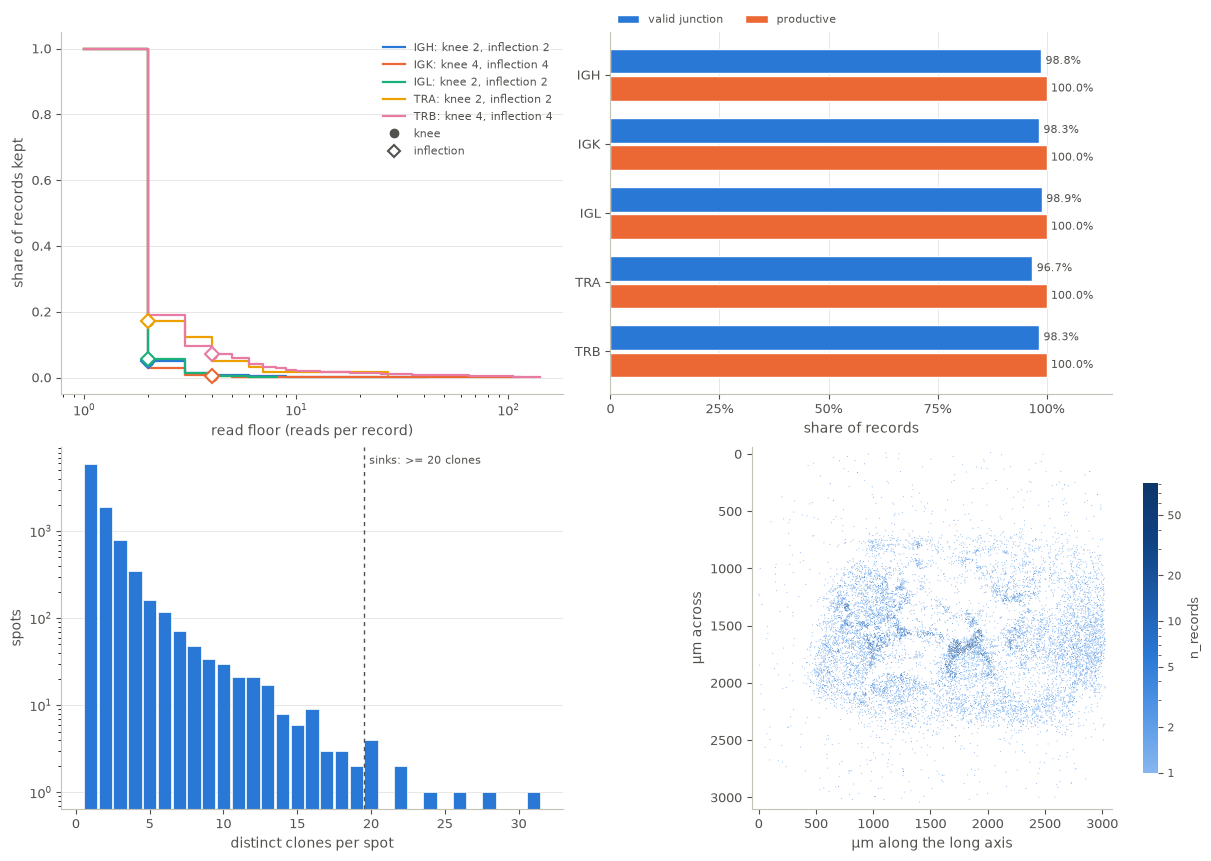

In [5]:
fig = pl.qc_panel(sp.air)
plt.show()

Records per µm² against the signed distance to the tissue edge (negative inside), relative to the tissue core:

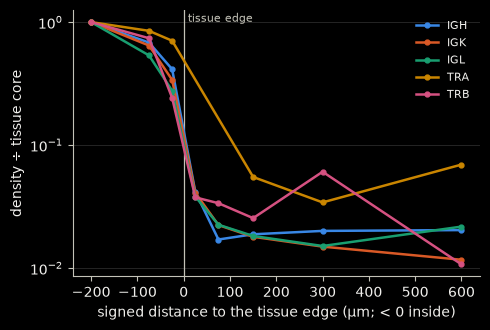

In [6]:
beads = pd.DataFrame({"x_um": sp.gex.obsm["spatial"][:, 0], "y_um": sp.gex.obsm["spatial"][:, 1]})
grid = tl.Grid.from_points(beads["x_um"], beads["y_um"], pixel_um=10.0)
tissue = tl.tissue_mask(beads[sp.gex.obs["in_tissue"].to_numpy(bool)], grid=grid)
edge = io.signed_distance_map(tissue.values.T, pixel_um=10.0, downsample=1, origin_um=grid.origin)  # mask[y, x]
profile = qc.density_profile(sp.air, edge, edges_um=(-300, -100, -50, 0, 50, 100, 200, 400, 800),
                             report_at_um=(600,))
ax = pl.density_profile(profile)
plt.show()

*Reading the QC.* Most molecules are kappa light chains, as expected for B-cell-rich tissue. 94–97% of BCR molecules
have one nanopore read: in this technology each read is a consensus of a whole molecule, so a read floor would only
throw data away. 98–99% of junctions pass the IMGT rules, most receptor beads carry one clone of a chain, and about
17% of molecules sit on off-tissue beads. Those cannot be in a cell and are removed next.

In [7]:
filt_sp = pp.filter_records(sp.air, valid_junction=True, productive=True, on_tissue=True)
filt_sp.report[["rule", "applied", "removed", "records", "spots", "clones"]]

,rule,applied,removed,records,spots,clones
0,input,True,0,25504,9604,2274
1,"valid junction (C...W/F, 20 aa, >= 5 aa)",True,413,25091,9534,2179
2,productive,True,0,25091,9534,2179
3,on tissue (in_tissue),True,4446,20645,7334,1930


### Cell types

GEO has no cell types for these beads, so each tissue bead gets the marker module it is most enriched for
(`gex.score_cell_types` with the built-in mouse immune modules; beads with fewer than two marker counts stay
unassigned). A 10 µm bead can hold parts of more than one cell, so "B" means "dominated by B-cell markers".

In [8]:
types_sp = gex.score_cell_types(sp.gex, markers="immune_mouse")
types_sp[["cell_type", "genes_used", "n_units", "pct_units"]]

,cell_type,genes_used,n_units,pct_units
0,B,"Cd79a,Cd79b,Ms4a1,Cd19,Pax5,Cr2,Fcer2a",4213,19.616334
1,GC_B,"Aicda,S1pr2,Gcsam,Rgs13,Mef2b",1528,7.114588
2,ASC,"Jchain,Xbp1,Prdm1,Sdc1,Mzb1",2799,13.032546
3,T,"Cd3e,Cd3d,Cd3g,Cd4,Cd8a,Cd8b1",1202,5.596685
4,Tfh,"Il21,Pdcd1,Icos,Tox2,Ascl2,Sh2d1a",92,0.428365
5,myeloid,"Lyz2,Cd68,C1qa,C1qb,Csf1r",2455,11.430833
6,stromal,"Col1a1,Col3a1,Pdpn,Ccl21a,Pecam1,Cdh5",1283,5.973832
7,erythroid,"Hba-a1,Hba-a2,Hbb-bs,Hbb-bt,Alas2,Gypa",76,0.353867
8,unassigned,,7829,36.452950


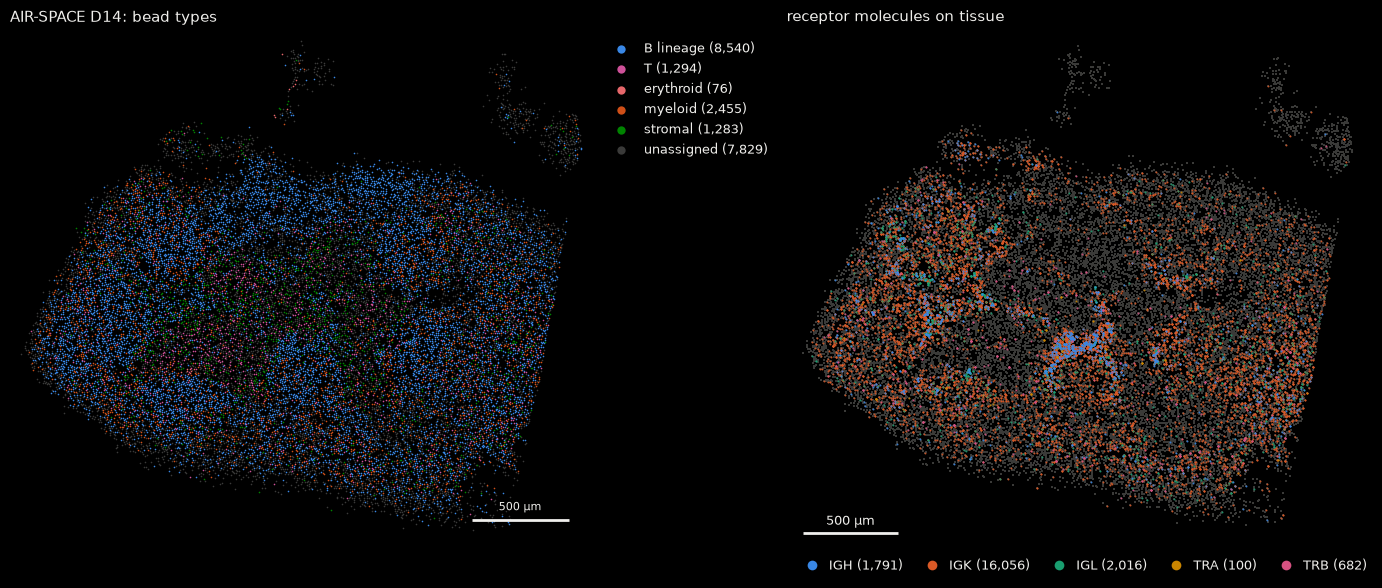

In [9]:
tissue_sp = sp.gex[sp.gex.obs["in_tissue"].to_numpy()].copy()
fold = {"B": "B lineage", "GC_B": "B lineage", "ASC": "B lineage", "Tfh": "T"}
tissue_sp.obs["bead type"] = tissue_sp.obs["cell_type"].astype(str).replace(fold)
fig, axes = plt.subplots(1, 2, figsize=(14, 7), layout="constrained")
pl.gex_map(tissue_sp, "bead type", ax=axes[0], title="AIR-SPACE D14: bead types")
pl.spatial_records(filt_sp.air, tissue_sp, color="locus", ax=axes[1], size=2, title="receptor molecules on tissue")
plt.show()

### One call

`spaclone.run` takes a `SpatialAIR`; we hand it the filtered molecules with the reader's GEX and metadata.

In [10]:
sp_f = io.SpatialAIR(filt_sp.air, sp.gex, sp.meta)
rep_sp = spaclone.run(sp_f, species="mouse")
print(rep_sp.verdict)
rep_sp.tests()[COLS]

Clone positions supported: clone identity follows position; clone maps and spatial clone statistics are licensed. Molecule level: signal — molecules sit on their own transcript / cell type more often than random placement (own_type_share (BCR, TCR)).


,test,locus,n,observed,chance,ratio,p_value,q_value,verdict,note
0,own_type_share,BCR,19520.0,0.635963,0.515720,1.233155,0.004975,0.004975,signal,cDNA-weighted spot placement; cell types obs['cell_type'...
1,own_type_share,TCR,782.0,0.163683,0.077948,2.099910,0.004975,0.004975,signal,cDNA-weighted spot placement; cell types obs['cell_type'...
2,colocalisation,IGH,1374.0,0.094330,0.033488,2.816854,0.004975,0.012438,signal,"stratified null, records units, 203 clones, top clone 19..."
3,colocalisation,TRB,472.0,0.012766,0.010833,1.178485,0.497512,0.497512,not detected,"stratified null, records units, 99 clones, top clone 33%..."
4,colocalisation,IGK,11150.0,0.044372,0.016360,2.712211,0.004975,NaN,info,"light chain, not a clone marker (shared CDR3s): informat..."
5,colocalisation,IGL,1110.0,0.028307,0.014542,1.946493,0.004975,NaN,info,"light chain, not a clone marker (shared CDR3s): informat..."
6,colocalisation,TRA,57.0,0.000000,0.007083,0.000000,1.000000,NaN,info,"light chain, not a clone marker (shared CDR3s): informat..."
7,pairing,IGH/IGK,1374.0,6.923584,3.358519,2.061499,0.004975,0.012438,signal,stratified null
8,pairing,IGH/IGL,1374.0,1.332217,1.313066,1.014585,0.457711,0.497512,not detected,stratified null
9,pairing,TRB/TRA,472.0,NaN,NaN,NaN,NaN,NaN,untestable,0 heavy / 0 light clones with >= 10 units (two of each n...


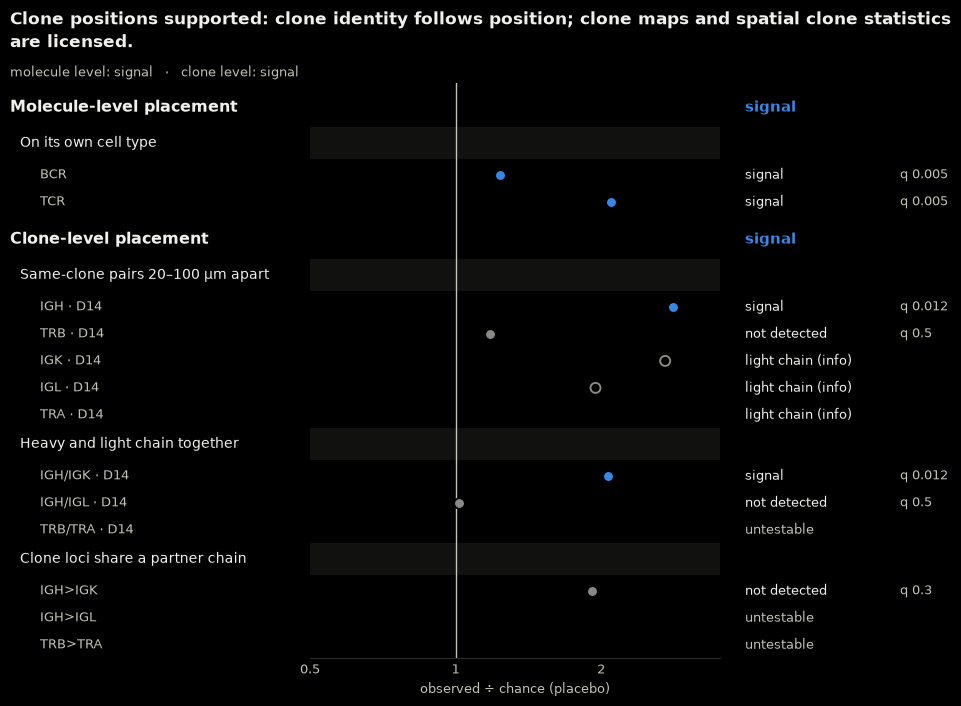

In [11]:
fig = rep_sp.plot()
plt.show()

*Reading the report.*

* **Same-clone co-localisation** (clone level; pairs 20–100 µm apart, clone labels shuffled within local Ig RNA
  strata): IGH clones sit together 2.8 times more often than the depth-matched placebo (q = 0.012); TRB is not
  detected. The light chains (IGK 2.7×, IGL 1.9×) are information only, because unrelated B cells share light-chain
  CDR3s.
* **Pairing** (clone level): heavy and kappa chains share 10 µm bins 2.1 times more often than heavy labels shuffled
  within clones-per-spot strata (q = 0.012); lambda partners are not detected, and the TCR pair has no testable clone.
* **Own cell type** (molecule level): 64% of BCR molecules sit on B-lineage beads against 52% when whole beads are
  placed at random in proportion to their cDNA (1.2×); TCR 16% against 7.8%.
* **Same spot** is not run: a 10 µm Curio bead is about the size of a cell, so it holds the constant-region RNA of its
  cell and of its neighbours whatever the receptor does, and the test would sit at its ceiling. It needs spots well
  below cell size (Stereo-seq DNBs, 0.5–2 µm).
* **Partner sharing** has too few testable heavy clonotypes (10 for kappa, fewer for the others).

Both levels pass, and the clone level licenses clone maps for this node.

`qc.pairing` called on its own gives the per-clone view, here for the heavy clones with at least 10 units:

In [12]:
pair_sp = qc.pairing(filt_sp.air, heavy=("IGH",), light=("IGK", "IGL"), min_units=10, n_perm=199, rng=0)
pair_sp.table[["heavy_locus", "light_locus", "n_heavy", "n_light", "statistic", "null_mean", "z", "p_value", "n_q05"]]

,heavy_locus,light_locus,n_heavy,n_light,statistic,null_mean,z,p_value,n_q05
0,IGH,IGK,25,194,6.649387,3.363863,21.650392,0.005,17
1,IGH,IGL,25,9,1.467490,1.302150,1.026836,0.160,0


Heavy clones share 10 µm bins with one kappa clone far more than heavy labels shuffled among spots of the same
crowding allow (z ≈ 22), and 17 of the 25 tested heavy clones have a kappa partner at q < 0.05. Lambda partners are too
few (9 clones) to test.

## 2. Stereo-XCR-seq LUAD, chip D06047A2

GSE328481 publishes the authors' final call of each segmented cell (CellBin), not molecules: a heavy-chain CDR3, a
light-chain CDR3 with its locus, TRA and TRB, and the authors' cell annotation. `io.from_cell_calls` turns those
columns into a receptor table (one row per cell and call) and keeps the expression matrix. It records that such data
cannot carry molecule-level evidence:

In [13]:
lu = io.from_cell_calls(LUAD_H5AD, cell_type_key="anno", technology="Stereo-XCR-seq LUAD (CellBin calls)")
print(lu.meta["note"])
print({k: lu.meta[k] for k in ("level", "molecule_level", "n_cells", "n_cells_with_call", "n_records")})
lu.air[["spot_id", "x_um", "y_um", "locus", "clone_id", "junction_aa", "cell_type"]].head()

per-cell calls of an upstream pipeline: no reads, UMIs or molecule positions, so molecule-level tests (same-spot GEX match, UMI match, read floor, swap rate) cannot be run; if the pipeline used cell types to assign calls, cell-type concordance is circular
{'level': 'cell_call', 'molecule_level': False, 'n_cells': 130469, 'n_cells_with_call': 8658, 'n_records': 13676}


,spot_id,x_um,y_um,locus,clone_id,junction_aa,cell_type
0,43,6904.0,2291.5,IGH,IGH|||CAKDWGTGWLFDYW,CAKDWGTGWLFDYW,plasma_cell
1,45,6901.5,2281.5,IGH,IGH|||CARLGPGNW,CARLGPGNW,plasma_cell
2,47,6897.0,2265.0,IGH,IGH|||CAKNYRFGSGSPLDSW,CAKNYRFGSGSPLDSW,plasma_cell
3,48,6895.5,2298.0,IGH,IGH|||CAKSAFSSGYGDYLDHW,CAKSAFSSGYGDYLDHW,plasma_cell
4,49,6895.0,2287.5,IGH,IGH|||CARFGPYSSTLYAFDVW,CARFGPYSSTLYAFDVW,plasma_cell


In [14]:
qc_lu = pp.qc_metrics(lu.air)
qc_lu.table.set_index("locus")[["n_records", "n_clones", "valid_share", "spots_per_clone_median", "spots_per_clone_max"]]

,n_records,n_clones,valid_share,spots_per_clone_median,spots_per_clone_max
locus,,,,,
IGH,6178,1012,0.986080,2.0,437.0
IGK,1809,349,0.995025,2.0,251.0
IGL,2392,366,0.978679,2.0,447.0
TRA,1495,50,0.996656,2.0,875.0
TRB,1802,73,0.998335,3.0,274.0


In [15]:
lu.gex.obs["cell_type"].value_counts()

cell_type
cancer_cell         84762
myeloid_cell        24996
fibroblast           7495
plasma_cell          3832
Tcell                3363
ciliated_cells       2819
epi                  1786
endothelial_cell      966
b_cell                420
mast_cell              30
Name: count, dtype: int64

Each cell carries at most one call per chain and there are no reads or UMIs, so `run` skips the molecule-level steps
(same spot, barcode sinks, read floor) and reports why. Own cell types are found automatically when a label contains
a lineage word ("B cell", "plasma", "T cells", ...); the authors' T-cell label is the single word `Tcell`, so we name
it with `own_types` (the BCR side stays automatic: `b_cell` and `plasma_cell`).

In [16]:
rep_lu = spaclone.run(lu, species="human", own_types={"TCR": ["Tcell"]})
print(rep_lu.verdict)
rep_lu.tests()[COLS]

Cell-type placement only: molecules sit on their own cell type / transcript, but clone-level placement was not detected at the power of these data (as expected under template switching between constant regions, or when too few molecules are in place); do not use clone maps until a clone-level test detects placement. Clone level: not detected — none of 5 testable row(s) in 2 tests reached BH q < 0.05 (colocalisation (IGH D06047A2, TRB D06047A2); pairing (IGH/IGK D06047A2, IGH/IGL D06047A2, TRB/TRA D06047A2)); a single positive row would have needed observed/chance >= 1.24 (colocalisation), 1.08 (pairing).


,test,locus,n,observed,chance,ratio,p_value,q_value,verdict,note
0,own_type_share,BCR,10233.0,0.494381,0.032743,15.098788,0.004975,0.004975,signal,uniform spot placement; cell types obs['cell_type']; own...
1,own_type_share,TCR,3289.0,0.928854,0.025602,36.280506,0.004975,0.004975,signal,uniform spot placement; cell types obs['cell_type']; own...
2,colocalisation,IGH,6092.0,0.004725,0.005001,0.944701,0.746269,0.756219,not detected,"stratified null, records units, 513 clones, top clone 5%..."
3,colocalisation,TRB,1799.0,0.031637,0.028337,1.116445,0.139303,0.348259,not detected,"stratified null, records units, 34 clones, top clone 20%..."
4,colocalisation,IGK,1800.0,0.014842,0.003969,3.739871,0.004975,NaN,info,"light chain, not a clone marker (shared CDR3s): informat..."
5,colocalisation,IGL,2341.0,0.008059,0.003752,2.147939,0.004975,NaN,info,"light chain, not a clone marker (shared CDR3s): informat..."
6,colocalisation,TRA,1490.0,0.023346,0.027329,0.854266,0.935323,NaN,info,"light chain, not a clone marker (shared CDR3s): informat..."
7,pairing,IGH/IGK,6092.0,2.218276,2.064639,1.074413,0.014925,0.074627,not detected,stratified null (p < 0.05 but BH q >= 0.05)
8,pairing,IGH/IGL,6092.0,2.304501,2.286855,1.007716,0.398010,0.663350,not detected,stratified null
9,pairing,TRB/TRA,1799.0,1.934732,2.031844,0.952205,0.756219,0.756219,not detected,stratified null


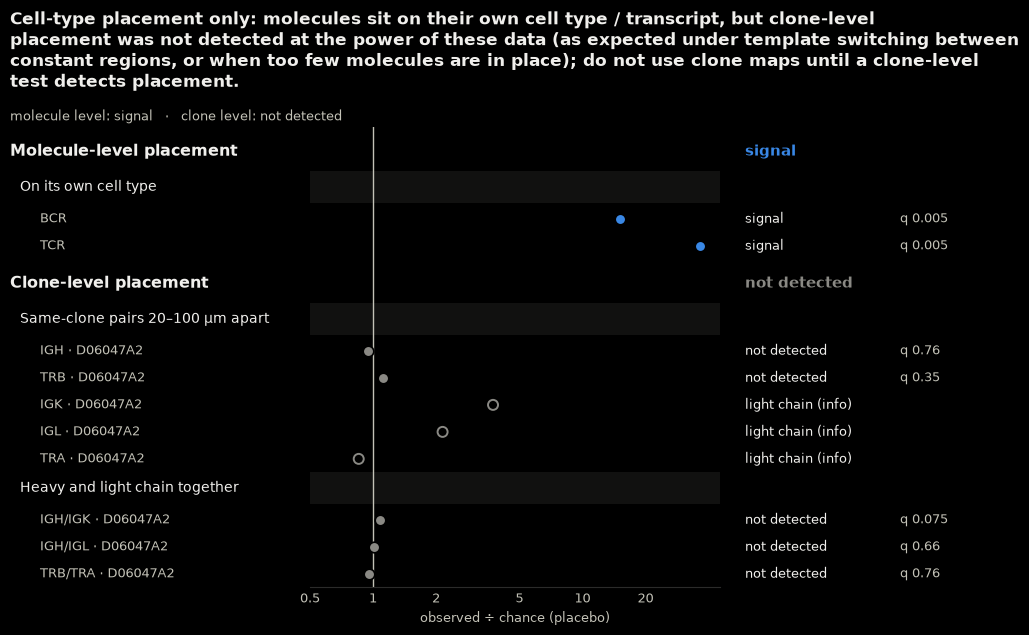

In [17]:
fig = rep_lu.plot()
plt.show()

*Reading the report.*

* **Heavy-chain clones** sit where random placement within Ig RNA strata puts them: IGH same-clone pairs 20–100 µm
  apart are 0.94 times the placebo (p = 0.75), with 513 clones contributing pairs. This is the clonal marker of a B
  cell, and it carries no positional signal.
* **Light-chain CDR3s** (IGK, IGL) co-localise 2–4 times above the placebo. A light-chain CDR3 is not a clonal marker:
  the same short kappa or lambda junction is made again and again by unrelated B cells, and the light-chain *type* of
  a call follows the cell's own kappa/lambda RNA in these data. This row says that something about light-chain calls is
  local, not that clones are in place.
* **Own cell type**: half of the BCR calls sit on B or plasma cells against 3% under random placement, and 93% of TCR
  calls on T cells against 3%. The calls were assigned to segmented cells by the authors' pipeline, which already knew the cell
  types; the reader's note warns that this concordance is then partly circular. Section 4 asks how much of it random
  placement reproduces once local Ig RNA is kept.
* **Pairing**: heavy and light calls of one cell do not pair beyond the chimera-aware null.

The package's verdict reads the data the same way: cell-type placement only, with the clone level not detected, so
no clone maps. The light-chain rows are information only, and the own-type rows decide the molecule level alone; by the
reading rule above, only the heavy-chain identity test speaks for clonal positions, and it is at chance.

## 3. Same-clone co-localisation side by side

`pl.placement` draws the observed statistic of every row against its null interval (2.5–97.5% of the placebo).

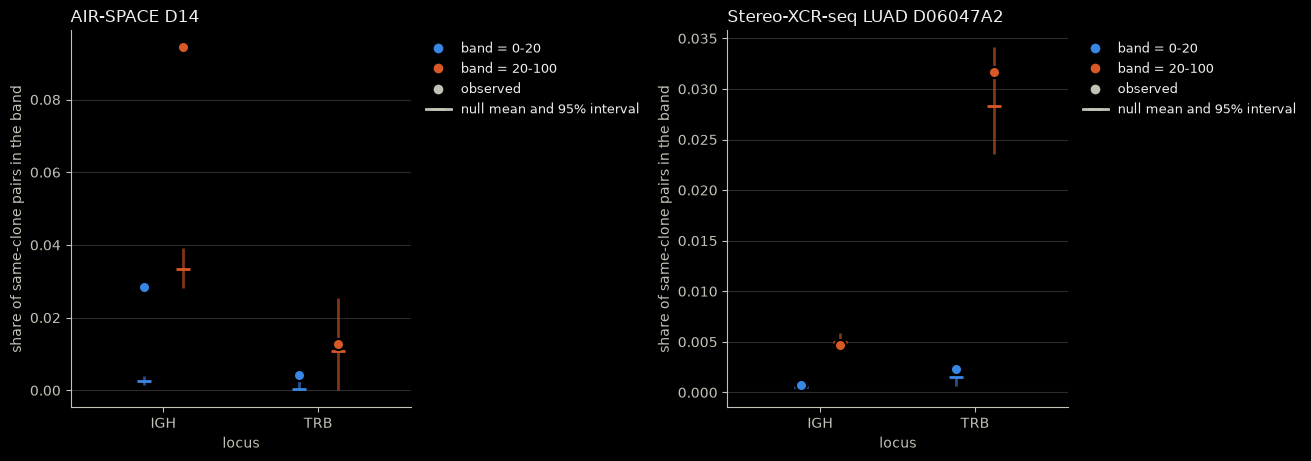

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
for ax, rep, title in ((axes[0], rep_sp, "AIR-SPACE D14"), (axes[1], rep_lu, "Stereo-XCR-seq LUAD D06047A2")):
    pl.placement(rep.results["colocalisation"], x="locus", hue="band", query="design == 'stratified'", ax=ax,
                 title=title)
plt.show()

In AIR-SPACE the heavy-chain clones stand far above their interval in both distance bands; in LUAD they sit at it. The
light chains are in `rep.results["colocalisation_light"]` (information only).

## 4. The placebo made concrete

Papers on spatial receptor methods show that their data are spatial with metrics like these:

1. receptor-positive cells correlate with B cells in 100 µm squares (Spearman r over squares);
2. IgH-positive cells express IGH constant genes;
3. IgH-positive cells are B-lineage cells;

and, less often, an identity metric:

4. cells of one clone sit near each other (share of same-clone pairs 20–100 µm apart, clones of 2–50 units).

`nulls.placebo` re-runs any such metric on random versions of the data. Two kinds of random data answer different
questions:

* **random placement** (`nulls.Relocate`): every IgH-positive unit (a cell in LUAD, a bead in AIR-SPACE), with all its
  calls, moves to another unit, either *anywhere* or only to units with the *same Ig RNA* (the amount of Ig
  constant-region RNA, in the strata 0, 1–2, 3–9, 10–29, 30–99, 100–299, ≥ 300 molecules of `nulls.IG_RNA_BINS`). The
  second is what a library whose barcodes come from random captured cDNA does: a swapped molecule lands where cDNA,
  here Ig cDNA, is. This is the placebo for metrics 1–3, which ask *where* receptor-positive units are.
* **random labelling** (`nulls.Permute`): every unit stays where it is and the clone labels are exchanged among units of
  the same Ig RNA stratum. This is the placebo for metric 4, which asks *which clone* a unit carries (and the null of
  `qc.colocalisation`).

A metric that its placebo reproduces cannot show that receptors sit in their own cells.

In [19]:
IGH_GENES = {"mouse": ["Ighm", "Ighd", "Ighg1", "Ighg2b", "Ighg2c", "Ighg3", "Igha", "Ighe"],
             "human": ["IGHM", "IGHD", "IGHG1", "IGHG2", "IGHG3", "IGHG4", "IGHA1", "IGHA2", "IGHE"]}


def unit_table(adata, species, b_types):
    """One row per tissue unit (bead or cell): position, Ig RNA stratum, IGH RNA and the B-lineage flag."""
    gex.ig_rna(adata, genes=species)  # obs["ig_rna"] and obs["ig_rna_bin"]
    keep = adata.obs["in_tissue"].to_numpy(bool) if "in_tissue" in adata.obs else np.ones(adata.n_obs, bool)
    a = adata[keep]
    genes = gex.ig_genes(a.var_names, IGH_GENES[species])
    return pd.DataFrame({
        "spot_id": a.obs_names.astype(str),
        "x_um": a.obsm["spatial"][:, 0],
        "y_um": a.obsm["spatial"][:, 1],
        "ig_bin": a.obs["ig_rna_bin"].astype(str).to_numpy(),
        "igh_rna": np.asarray(a[:, genes].X.sum(axis=1)).ravel(),
        "b_lineage": a.obs["cell_type"].astype(str).isin(b_types).to_numpy(),
    })


units_sp = unit_table(sp.gex, "mouse", ["B", "GC_B", "ASC"])
units_lu = unit_table(lu.gex, "human", ["b_cell", "plasma_cell"])
# one row per (unit, clone): several IGH molecules of one clone on one bead count once
igh_sp = (filt_sp.air.query("locus == 'IGH'").drop_duplicates(["spot_id", "clone_id"])
          .merge(units_sp[["spot_id", "ig_bin"]], on="spot_id"))
igh_lu = pp.filter_records(lu.air).air.query("locus == 'IGH'").merge(units_lu[["spot_id", "ig_bin"]], on="spot_id")
print(f"AIR-SPACE: {len(igh_sp):,} IGH (bead, clone) units on {igh_sp.spot_id.nunique():,} of {len(units_sp):,} tissue beads")
print(f"LUAD:      {len(igh_lu):,} IGH calls on {igh_lu.spot_id.nunique():,} of {len(units_lu):,} cells")

AIR-SPACE: 1,404 IGH (bead, clone) units on 1,137 of 21,477 tissue beads
LUAD:      6,092 IGH calls on 6,092 of 130,469 cells


The statistic is one function of a receptor table that computes all four metrics from scratch, so the placebo is
never partial: every random data set goes through exactly the same steps as the observed one.

In [20]:
def same_clone_share(a, lo_um=20.0, hi_um=100.0, max_units=50):
    """Share of same-clone (spot, clone) unit pairs that are lo_um-hi_um apart, over clones of 2-max_units units."""
    u = a.drop_duplicates(["spot_id", "clone_id"])
    size = u["clone_id"].map(u["clone_id"].value_counts())
    u = u[(size >= 2) & (size <= max_units)]
    codes = pd.factorize(u["clone_id"])[0]
    xy = u[["x_um", "y_um"]].to_numpy()
    pairs = cKDTree(xy).query_pairs(hi_um, output_type="ndarray")
    pairs = pairs[codes[pairs[:, 0]] == codes[pairs[:, 1]]]
    within = (np.linalg.norm(xy[pairs[:, 0]] - xy[pairs[:, 1]], axis=1) >= lo_um).sum()
    n = np.bincount(codes)
    return within / (n * (n - 1) // 2).sum()


def published_metrics(units, square_um=100.0):
    """A statistic for nulls.placebo: the four metrics of an IGH receptor table placed on `units`."""
    lookup = units.set_index("spot_id")
    square = lambda d: (d.x_um // square_um).astype(int).astype(str) + "_" + (d.y_um // square_um).astype(int).astype(str)
    b_per_square = units["b_lineage"].groupby(square(units)).sum()

    def statistic(a):
        u = a.drop_duplicates("spot_id")  # one row per IgH-positive cell or bead
        n_per_square = square(u).value_counts().reindex(b_per_square.index, fill_value=0)
        return {
            "1 IgH+ units ~ B cells per 100 µm (r)": spearmanr(n_per_square, b_per_square).statistic,
            "2 IgH+ units expressing IGH": float((u.spot_id.map(lookup.igh_rna) > 0).mean()),
            "3 IgH+ units that are B lineage": float(u.spot_id.map(lookup.b_lineage).mean()),
            "4 same-clone pairs 20-100 µm": same_clone_share(a),
        }

    return statistic


stat_sp, stat_lu = published_metrics(units_sp), published_metrics(units_lu)
pd.DataFrame({"AIR-SPACE D14": stat_sp(igh_sp), "LUAD D06047A2": stat_lu(igh_lu)}).round(4)

,AIR-SPACE D14,LUAD D06047A2
1 IgH+ units ~ B cells per 100 µm (r),0.4951,0.6619
2 IgH+ units expressing IGH,0.9965,0.9117
3 IgH+ units that are B lineage,0.5858,0.5758
4 same-clone pairs 20-100 µm,0.0964,0.0047


Every metric looks good on both data sets. Metric 4 is the statistic of the trust reports' IGH co-localisation on
(bead or cell, clone) units: 0.0047 for LUAD, as in its report; 0.096 for AIR-SPACE, against 0.094 in its report,
which counts molecules after removing barcode sinks.

Now the placebos. `nulls.compare_designs` runs `nulls.placebo` under each design (200 random data sets each, seeded)
and stacks the tables.

In [21]:
def designs(units):
    slots = units[["spot_id", "x_um", "y_um", "ig_bin"]]
    return {
        "move units anywhere": nulls.Relocate(slots),
        "move units, same Ig RNA": nulls.Relocate(slots, within="ig_bin"),
        "swap clone labels, same Ig RNA": nulls.Permute("clone_id", within="ig_bin"),
    }


res_sp = nulls.compare_designs(stat_sp, igh_sp, designs(units_sp), n_perm=200, rng=1)
res_lu = nulls.compare_designs(stat_lu, igh_lu, designs(units_lu), n_perm=200, rng=2)
summary = pd.concat([res_sp.table.assign(data="AIR-SPACE D14"), res_lu.table.assign(data="LUAD D06047A2")])
summary["cell"] = [f"{o / m:.2f} (p {p:.3f})" for o, m, p in zip(summary.observed, summary.null_mean, summary.p_value)]
print("observed ÷ placebo mean (Monte-Carlo p, one-sided)")
summary.pivot_table(index=["component", "data"], columns="design", values="cell", aggfunc="first")[
    list(designs(units_sp))]

observed ÷ placebo mean (Monte-Carlo p, one-sided)


design                                              move units anywhere move units, same Ig RNA swap clone labels, same Ig RNA
component                             data                                                                                    
1 IgH+ units ~ B cells per 100 µm (r) AIR-SPACE D14      1.03 (p 0.358)          0.70 (p 1.000)                 1.00 (p 1.000)
                                      LUAD D06047A2      3.66 (p 0.005)          1.09 (p 0.005)                 1.00 (p 1.000)
2 IgH+ units expressing IGH           AIR-SPACE D14      1.07 (p 0.005)          1.01 (p 0.010)                 1.00 (p 1.000)
                                      LUAD D06047A2      1.43 (p 0.005)          1.02 (p 0.005)                 1.00 (p 1.000)
3 IgH+ units that are B lineage       AIR-SPACE D14      1.47 (p 0.005)          0.94 (p 1.000)                 1.00 (p 1.000)
                                      LUAD D06047A2     17.61 (p 0.005)          2.45 (p 0.005)                 1.00 (p 1.000)
4 same-clone pairs 20-100 µm          AIR-SPACE D14     13.51 (p 0.005)          4.49 (p 0.005)                 2.68 (p 0.005)
                                      LUAD D06047A2      3.56 (p 0.005)          1.34 (p 0.005)                 0.94 (p 0.746)

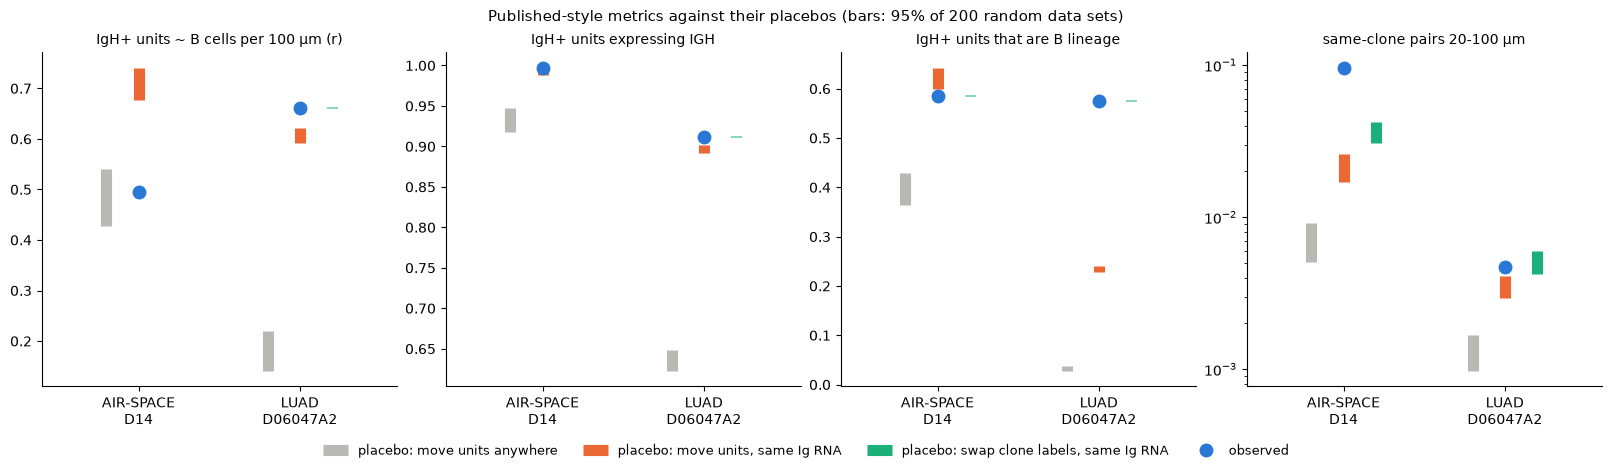

In [22]:
colours = {"move units anywhere": "#b9b8b3", "move units, same Ig RNA": "#eb6834",
           "swap clone labels, same Ig RNA": "#1baf7a"}
datasets = {"AIR-SPACE D14": res_sp.table, "LUAD D06047A2": res_lu.table}
fig, axes = plt.subplots(1, 4, figsize=(16, 4.6), layout="constrained")
for ax, metric in zip(axes, res_sp.table.component.unique()):
    for i, (name, tab) in enumerate(datasets.items()):
        t = tab[tab.component == metric]
        for j, (design, colour) in enumerate(colours.items()):
            r = t[t.design == design].iloc[0]
            lo, hi = r.null_lo, max(r.null_hi, r.null_lo + 1e-3 * abs(r.observed))  # draw zero-width nulls visibly
            ax.plot([i + (j - 1) * 0.2] * 2, [lo, hi], color=colour, lw=8, solid_capstyle="butt",
                    label=f"placebo: {design}" if i == 0 else None)
        ax.plot(i, t.observed.iloc[0], "o", color="#2a78d6", ms=9, label="observed" if i == 0 else None, zorder=3)
    ax.set_xticks([0, 1], [n.replace(" ", "\n", 1) for n in datasets])
    ax.set_xlim(-0.6, 1.6)
    ax.set_title(metric[2:], fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
axes[3].set_yscale("log")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=4, frameon=False, fontsize=9)
fig.suptitle("Published-style metrics against their placebos (bars: 95% of 200 random data sets)", fontsize=11)
plt.show()

*Reading the placebos.* The bars are where each metric falls on the random data sets; the dot is the observed value.

* **Metrics 1 and 2** (density, expression) are reproduced once local Ig RNA is kept (orange). In AIR-SPACE,
  placement within Ig RNA gives a *higher* density correlation than observed (0.71 against 0.50) and the same
  expression share (99%); in LUAD it gives 91% of the observed correlation (0.61 against 0.66) and 98% of the expression
  share. The small excesses left in LUAD are significant with 6,000 calls, but a metric that random placement
  reproduces to within a few percent cannot carry the claim that receptors sit in their own cells. Placing units
  anywhere (grey) is too weak a null and makes both metrics look like strong evidence.
* **Metric 3** (on B-lineage units) ranks the data sets the wrong way round: AIR-SPACE receptor beads are B lineage as
  often as random beads of the same Ig RNA (0.59 against 0.62), whereas LUAD calls sit on B or plasma cells 2.4 times
  more often than random cells of the same Ig RNA. The authors' pipeline assigned calls to segmented cells with their
  annotation at hand, which can produce this excess by construction.
* **Metric 4** (identity) needs the labelling placebo (green): with every unit kept in place and clone labels swapped
  within Ig RNA strata, AIR-SPACE same-clone pairs are 2.7 times the placebo and LUAD's sit at it (0.94, p = 0.75), as
  in the trust reports. Moving units (orange) is the wrong null for this question: it also scatters the IgH-positive
  units themselves, which sit in plasma-cell aggregates, so even LUAD looks 1.3 times "clustered" (p = 0.005). For
  metrics 1–3 the green bar sits exactly on the observed value: those metrics do not look at which clone a unit
  carries at all. What a design keeps fixed decides what a test can conclude; `05_custom_placebo` goes into this.

The p-values in the table have a floor of 1/201 = 0.005 with 200 random data sets: "far above" and "just above" both
read 0.005, so read the ratio and the intervals, not only p.

## Summary

| | AIR-SPACE D14 | Stereo-XCR-seq LUAD D06047A2 |
|---|---|---|
| Heavy-chain clones together (20–100 µm, labels swapped within Ig RNA) | 2.8× placebo, q = 0.012 | 0.94× placebo, p = 0.75 |
| Light-chain CDR3s together | 1.9–2.7× | 2.1–3.7× (not a clonal marker) |
| Heavy/light pairing | 2.1× (kappa, q = 0.012); 17 of 25 large heavy clones with a kappa partner | not detected (1.07×, q = 0.07) |
| Same spot as its own transcript | not run: 10 µm beads are cell-sized | not possible (cell-level calls) |
| Density and expression metrics (1, 2) | reproduced by placement within Ig RNA | 91–98% reproduced by placement within Ig RNA |
| On B-lineage units (3) | equal to placement within Ig RNA | 2.4× placement within Ig RNA (calls assigned with cell types) |
| Verdict of `spaclone.run` | clone positions supported | cell-type placement only; no clone maps |

AIR-SPACE positions carry clonal information. In the LUAD chip the heavy-chain identities are placed as random
labelling within Ig RNA strata would place them; use its receptor sequences as a bulk repertoire of the chip, not as
positions of clones.

**Caveats.** One node and one chip are shown; the same calls on the other AIR-SPACE nodes and LUAD chips are a loop
over files (in the 2026-10 analysis behind this package, D06053D2, the largest LUAD chip, was the one chip of eleven
whose heavy chains co-localised above this placebo). The depth strata are each unit's own Ig RNA; a placebo that also
keeps the neighbourhood (`Relocate(window_um=...)`) is stricter still, see `05_custom_placebo`. A "no signal" result
bounds what the data can show; it does not prove that every receptor is misplaced.